# GSFC Beamline Forward Model

1. Get {Al,Ti,Fe} spectra as provided by Athiray
2. Put into spectral cube with appropriate spot size
3. Interpolate effective area for +/-5 orders for slot
4. Map to detector

## Useful Parameters

- 30 s exposures
- 120 mA current (or 150 mA?)
    - Ask Athiray and Albert 
- Spectra I saw today was comprised of 58 frames (with 30 s exposures) I think?
- Spot on detector is about 2 arcseconds (how many pixels?)
    - Start with 1, compare with data to get width  

In [76]:
import pathlib

import astropy.wcs
import astropy.units as u
import astropy.table
import ndcube
import numpy as np
import matplotlib.pyplot as plt
import sunpy.map

from astropy.coordinates import SkyCoord
from astropy.wcs.utils import wcs_to_celestial_frame
from astropy.visualization import quantity_support, ImageNormalize, LogStretch
from mocksipipeline.instrument.configuration import moxsi_built
from scipy.interpolate import PchipInterpolator
from sunpy.coordinates import Helioprojective, get_earth
from synthesizAR.instruments.util import add_wave_keys_to_header, extend_celestial_wcs

from mocksipipeline.modeling import convolve_with_response, project_spectral_cube
from mocksipipeline.instrument.configuration import moxsi_built
from mocksipipeline.util import stack_components, build_moxsi_collection
from mocksipipeline.visualization import plot_detector_image, plot_labeled_spectrum

In [10]:
def load_target_spectra(filename, angular_size):
    "Load the fitted models derived from the beamline spectra"
    beamline_currents = {
        'Al': 15 * u.milliampere,
        'Fe': 10 * u.milliampere,
        'Ti': 10 * u.milliampere,
    }
    line_labels = {
        'Al': ['Mg Ka', 'Al Ka', 'Si Ka'],
        'Fe': ['Si Ka', 'Fe Ka', 'Fe Kb'],
        'Ti': ['Si Ka', 'Ti Ka', 'Ti Kb'],
    }
    flux_unit = u.Unit('ph / (s cm2 keV)')
    #tables = []
    #for filename in sorted(pathlib.Path(data_dir).glob('*_target_model.txt')):
    filename = pathlib.Path(filename)
    tab = astropy.table.QTable.read(filename, format='ascii.no_header', data_start=2)
    tab.rename_column('col1', 'Energy')
    tab.rename_column('col2', 'Continuum')
    tab['Energy'].unit = 'keV'
    tab['Continuum'].unit = flux_unit
    target = filename.name.split('_')[0]
    for i in range(len(tab.columns)-2):
        tab.rename_column(f'col{i+3}', line_labels[target][i])
        tab[line_labels[target][i]].unit = flux_unit
    tab['Target'] = tab['Energy'].shape[0]*[target,]
    tab['Wavelength'] = tab['Energy'].to('Angstrom', equivalencies=u.spectral())
    tab = tab[['Target', 'Energy', 'Wavelength', 'Continuum']+tab.colnames[2:-2]]
    for cname in tab.colnames[3:]:
        tab[cname] /= beamline_currents[target]
        tab[cname] /= angular_size.to('steradian')
        tab[cname] *= np.fabs(np.gradient(tab['Energy']) / np.gradient(tab['Wavelength']))
    tab['Total'] = u.Quantity(np.zeros(tab['Energy'].shape), tab['Continuum'].unit)
    for cname in tab.colnames[3:]:
        tab['Total'] += tab[cname]
    #tables.append(tab[['Target', 'Energy', 'Wavelength', 'Continuum']+tab.colnames[2:-2]])
    #return astropy.table.vstack(tables)
    return tab

In [11]:
assumed_angular_size = 4*u.arcsec**2
al_target_spectra = load_target_spectra('data/Al_target_model.txt', assumed_angular_size)
fe_target_spectra = load_target_spectra('data/Fe_target_model.txt', assumed_angular_size)
ti_target_spectra = load_target_spectra('data/Ti_target_model.txt', assumed_angular_size)

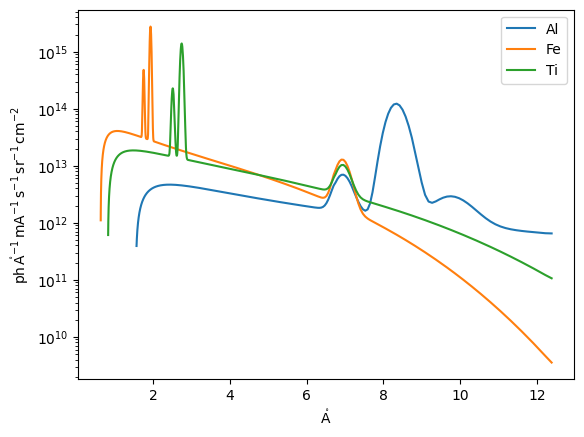

In [12]:
with quantity_support():
    plt.plot(al_target_spectra['Wavelength'], al_target_spectra['Total'], label=al_target_spectra['Target'][0])
    plt.plot(fe_target_spectra['Wavelength'], fe_target_spectra['Total'], label=fe_target_spectra['Target'][0])
    plt.plot(ti_target_spectra['Wavelength'], ti_target_spectra['Total'], label=ti_target_spectra['Target'][0])
    plt.yscale('log')
    plt.legend()

In [89]:
def make_spectral_cube(table):
    """
    Make an NDCube from a 1D spectra.
    """
    earth_observer = get_earth('2020-01-01')
    ref_coord = SkyCoord(0, 0, unit='arcsec', frame=Helioprojective(observer=earth_observer))
    array_size = (30, 130)  # this should always be even and be >> bigger than the PSF size
    delta_wave = np.fabs(np.diff(table['Wavelength'])).min().to_value('Angstrom')
    common_wavelength = np.arange(table['Wavelength'].min().to_value('Angstrom'),
                                  table['Wavelength'].max().to_value('Angstrom'),
                                  delta_wave) * u.Angstrom
    wavelength = common_wavelength #table['Wavelength']
    f_interp = PchipInterpolator(table['Energy'].to_value('keV'), table['Total'].value, extrapolate=True)
    data = f_interp(common_wavelength.to_value('keV', equivalencies=u.spectral())) * table['Total'].unit
    data_array = np.zeros(wavelength.shape+array_size) * data.unit
    #data_array[:, array_size[0]//2-1:array_size[0]//2+1, array_size[1]//2-1:array_size[1]//2+1] = data[:, None, None]
    data_array[:, array_size[0]//2-3:array_size[0]//2+3, array_size[1]//2-3:array_size[1]//2+3] = data[:, None, None]
    header = sunpy.map.make_fitswcs_header(
        array_size,
        ref_coord,
        scale=moxsi_built.optical_design.spatial_plate_scale,
        unit=data.unit,
    )
    header = add_wave_keys_to_header(wavelength, header)
    wcs = astropy.wcs.WCS(header=header)
    return ndcube.NDCube(data_array, wcs=wcs, meta=header)

In [90]:
al_target_cube = make_spectral_cube(al_target_spectra)
fe_target_cube = make_spectral_cube(fe_target_spectra)
ti_target_cube = make_spectral_cube(ti_target_spectra)

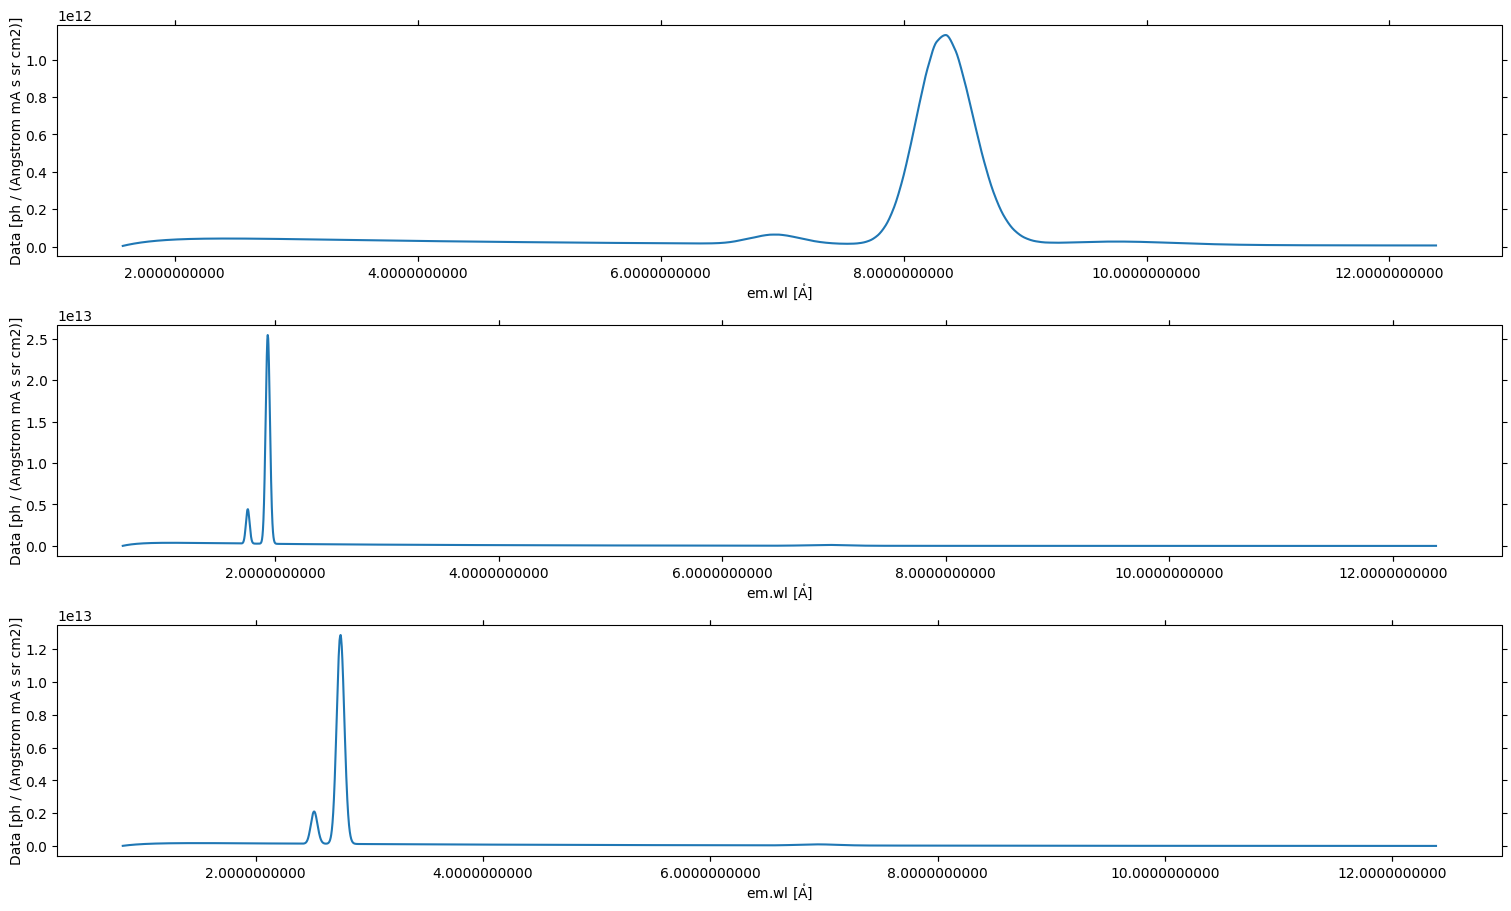

In [92]:
fig = plt.figure(figsize=(15,9), layout='constrained')
for i,cube in enumerate([al_target_cube, fe_target_cube, ti_target_cube]):
    cube_r = cube.rebin((1,30,130)).squeeze()
    ax = fig.add_subplot(3,1,i+1,projection=cube_r.wcs)
    cube_r.plot(axes=ax,axes_units=['Angstrom'])
#ax = al_target_cube.rebin((1,11,11)).squeeze().plot(axes_units=['Angstrom'])
#fe_target_cube.rebin((1,11,11)).squeeze().plot(axes_units=['Angstrom'])
#ti_target_cube.rebin((1,11,11)).squeeze().plot(axes_units=['Angstrom'])
#ax.set_yscale('log')

Now, project them into the cube

In [93]:
dt = 60 * u.s
total_time = 1*u.h

In [94]:
current_setting = 130*u.milliampere

In [95]:
moxsi_components = {}
for mc in moxsi_built:
    print(mc.name, mc.spectral_order)
    instr_cube = convolve_with_response(al_target_cube*current_setting, mc, include_gain=False)
    det_cube = project_spectral_cube(instr_cube,
                                     mc,
                                     wcs_to_celestial_frame(al_target_cube.wcs).observer,
                                     exposure=dt,
                                     integration=total_time,
                                     include_psf=True,
                                     include_charge_spreading=False,
                                     apply_gain_conversion=True,
                                     apply_electron_conversion=True)
    moxsi_components[f'{mc.name}_{mc.spectral_order}'] = det_cube

filtergram_1 0


/Users/wtbarnes/miniforge3/envs/moxsi-science/lib/python3.13/site-packages/astropy/units/equivalencies.py:162: RuntimeWarning: divide by zero encountered in divide
  (si.m, si.J, lambda x: hc / x),
/Users/wtbarnes/miniforge3/envs/moxsi-science/lib/python3.13/site-packages/astropy/units/equivalencies.py:162: RuntimeWarning: divide by zero encountered in divide
  (si.m, si.J, lambda x: hc / x),
/Users/wtbarnes/miniforge3/envs/moxsi-science/lib/python3.13/site-packages/astropy/units/equivalencies.py:162: RuntimeWarning: divide by zero encountered in divide
  (si.m, si.J, lambda x: hc / x),
  'angstrom' -> 'Angstrom'. [astropy.wcs.wcs]


filtergram_2 0


/Users/wtbarnes/miniforge3/envs/moxsi-science/lib/python3.13/site-packages/astropy/units/equivalencies.py:162: RuntimeWarning: divide by zero encountered in divide
  (si.m, si.J, lambda x: hc / x),
/Users/wtbarnes/miniforge3/envs/moxsi-science/lib/python3.13/site-packages/astropy/units/equivalencies.py:162: RuntimeWarning: divide by zero encountered in divide
  (si.m, si.J, lambda x: hc / x),
/Users/wtbarnes/miniforge3/envs/moxsi-science/lib/python3.13/site-packages/astropy/units/equivalencies.py:162: RuntimeWarning: divide by zero encountered in divide
  (si.m, si.J, lambda x: hc / x),
  'angstrom' -> 'Angstrom'. [astropy.wcs.wcs]


filtergram_3 0


/Users/wtbarnes/miniforge3/envs/moxsi-science/lib/python3.13/site-packages/astropy/units/equivalencies.py:162: RuntimeWarning: divide by zero encountered in divide
  (si.m, si.J, lambda x: hc / x),
/Users/wtbarnes/miniforge3/envs/moxsi-science/lib/python3.13/site-packages/astropy/units/equivalencies.py:162: RuntimeWarning: divide by zero encountered in divide
  (si.m, si.J, lambda x: hc / x),
/Users/wtbarnes/miniforge3/envs/moxsi-science/lib/python3.13/site-packages/astropy/units/equivalencies.py:162: RuntimeWarning: divide by zero encountered in divide
  (si.m, si.J, lambda x: hc / x),
  'angstrom' -> 'Angstrom'. [astropy.wcs.wcs]


... (90 outputs left out)

spectrogram_slot 10


/Users/wtbarnes/miniforge3/envs/moxsi-science/lib/python3.13/site-packages/astropy/units/equivalencies.py:162: RuntimeWarning: divide by zero encountered in divide
  (si.m, si.J, lambda x: hc / x),
/Users/wtbarnes/miniforge3/envs/moxsi-science/lib/python3.13/site-packages/astropy/units/equivalencies.py:162: RuntimeWarning: divide by zero encountered in divide
  (si.m, si.J, lambda x: hc / x),
/Users/wtbarnes/miniforge3/envs/moxsi-science/lib/python3.13/site-packages/astropy/units/equivalencies.py:162: RuntimeWarning: divide by zero encountered in divide
  (si.m, si.J, lambda x: hc / x),
  'angstrom' -> 'Angstrom'. [astropy.wcs.wcs]


spectrogram_slot 11


/Users/wtbarnes/miniforge3/envs/moxsi-science/lib/python3.13/site-packages/astropy/units/equivalencies.py:162: RuntimeWarning: divide by zero encountered in divide
  (si.m, si.J, lambda x: hc / x),
/Users/wtbarnes/miniforge3/envs/moxsi-science/lib/python3.13/site-packages/astropy/units/equivalencies.py:162: RuntimeWarning: divide by zero encountered in divide
  (si.m, si.J, lambda x: hc / x),
/Users/wtbarnes/miniforge3/envs/moxsi-science/lib/python3.13/site-packages/astropy/units/equivalencies.py:162: RuntimeWarning: divide by zero encountered in divide
  (si.m, si.J, lambda x: hc / x),
  'angstrom' -> 'Angstrom'. [astropy.wcs.wcs]


In [100]:
moxsi_components['all_components'] = stack_components(
    [moxsi_components[k] for k in moxsi_components if k!='all_components'],
    wcs_index=15
)

In [97]:
def build_moxsi_collection_mod(image_dict):
    all_components = image_dict.pop('all_components')
    return ndcube.NDCollection(
        {k: ndcube.NDCube(all_components.data, wcs=v.wcs, meta=v.meta, unit=v.unit,)
         for k,v in image_dict.items()},
        aligned_axes=(0,1,2)
    )

moxsi_col = build_moxsi_collection_mod(moxsi_components)

In [101]:
norm = ImageNormalize(vmin=0, )

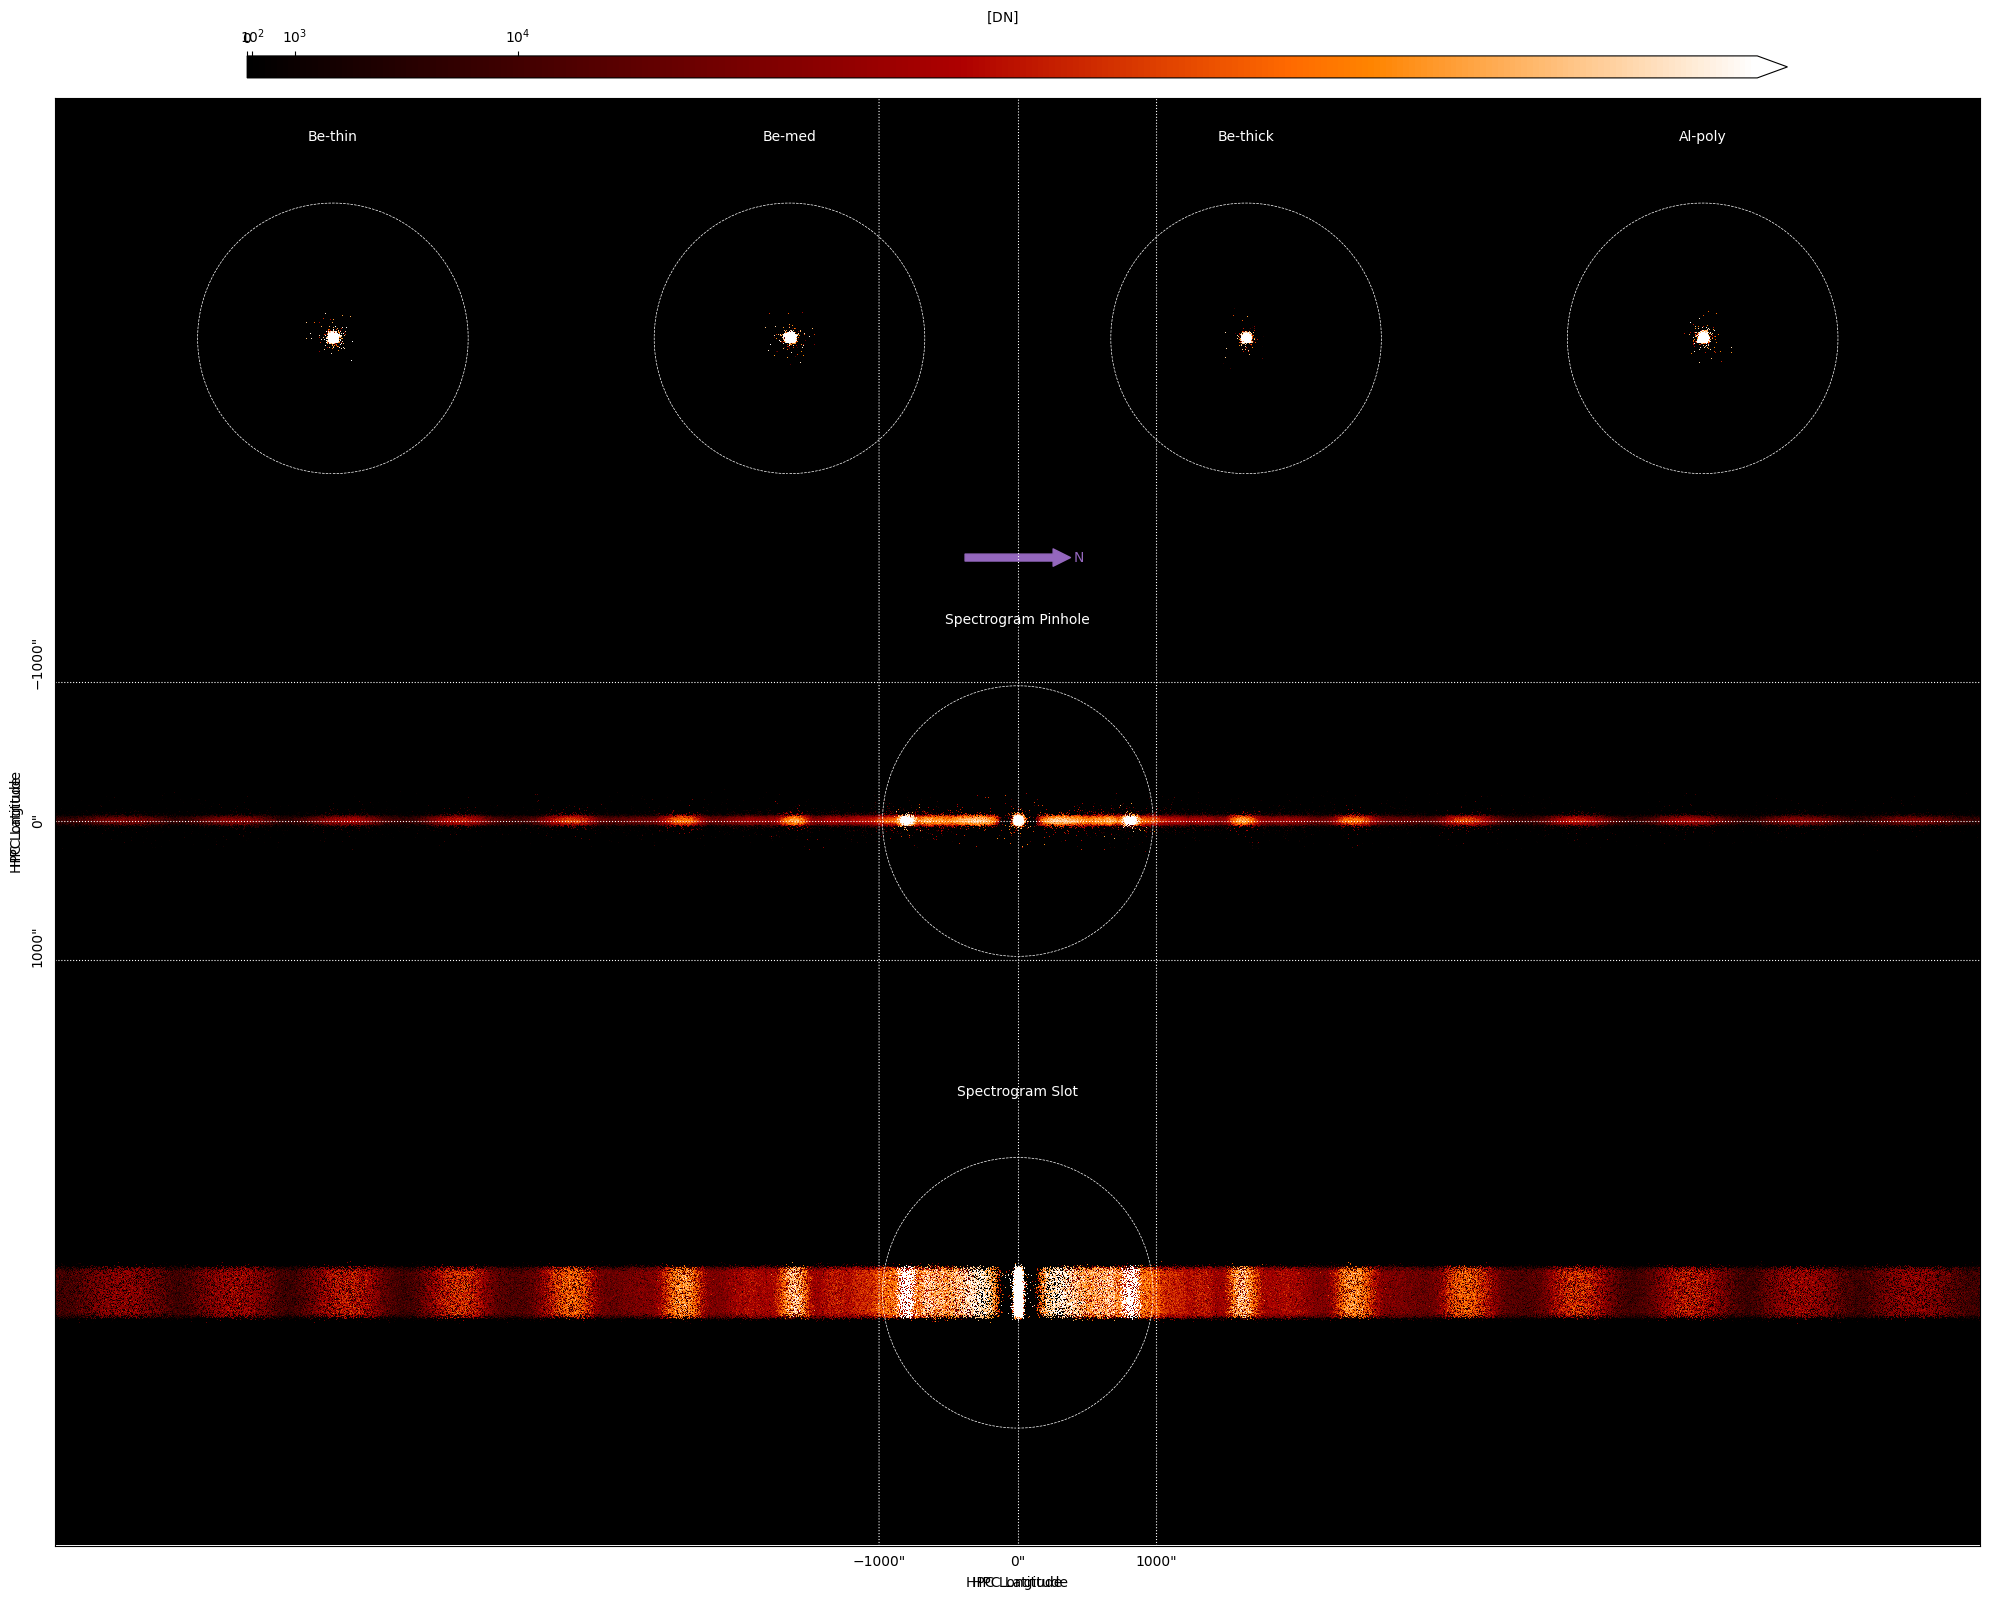

In [103]:
fig = plot_detector_image(moxsi_components, prime_key='all_components', interpolation='none')

Text(0.5, 0, 'MOXSI Detector Pixel')

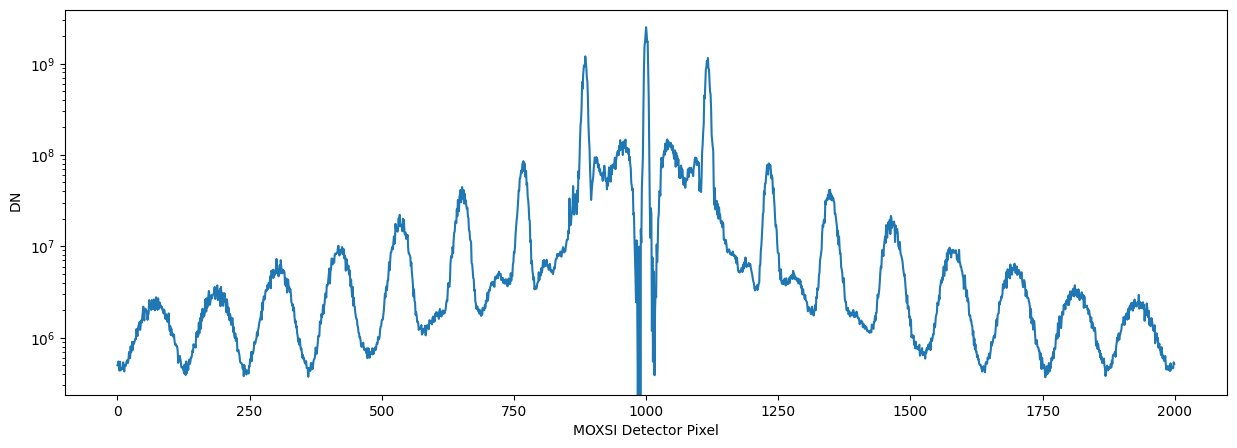

In [107]:
plt.figure(figsize=(15,5))
with quantity_support():
    plt.plot(moxsi_components['all_components'][0][:300,:].quantity.sum(axis=0))
plt.yscale('log')
plt.xlabel('MOXSI Detector Pixel')

In [43]:
summed_det_cube = stack_components(moxsi_components, wcs_index=12)

In [44]:
summed_det_cube

NDCube
------
Shape: (2353, 1504, 2000)
Physical Types of Axes: [('custom:pos.helioprojective.lon', 'custom:pos.helioprojective.lat', 'em.wl'), ('custom:pos.helioprojective.lon', 'custom:pos.helioprojective.lat'), ('custom:pos.helioprojective.lon', 'custom:pos.helioprojective.lat')]
Unit: DN
Data Type: float64

In [ ]:
plot_labeled_spectrum()

##  Sandbox

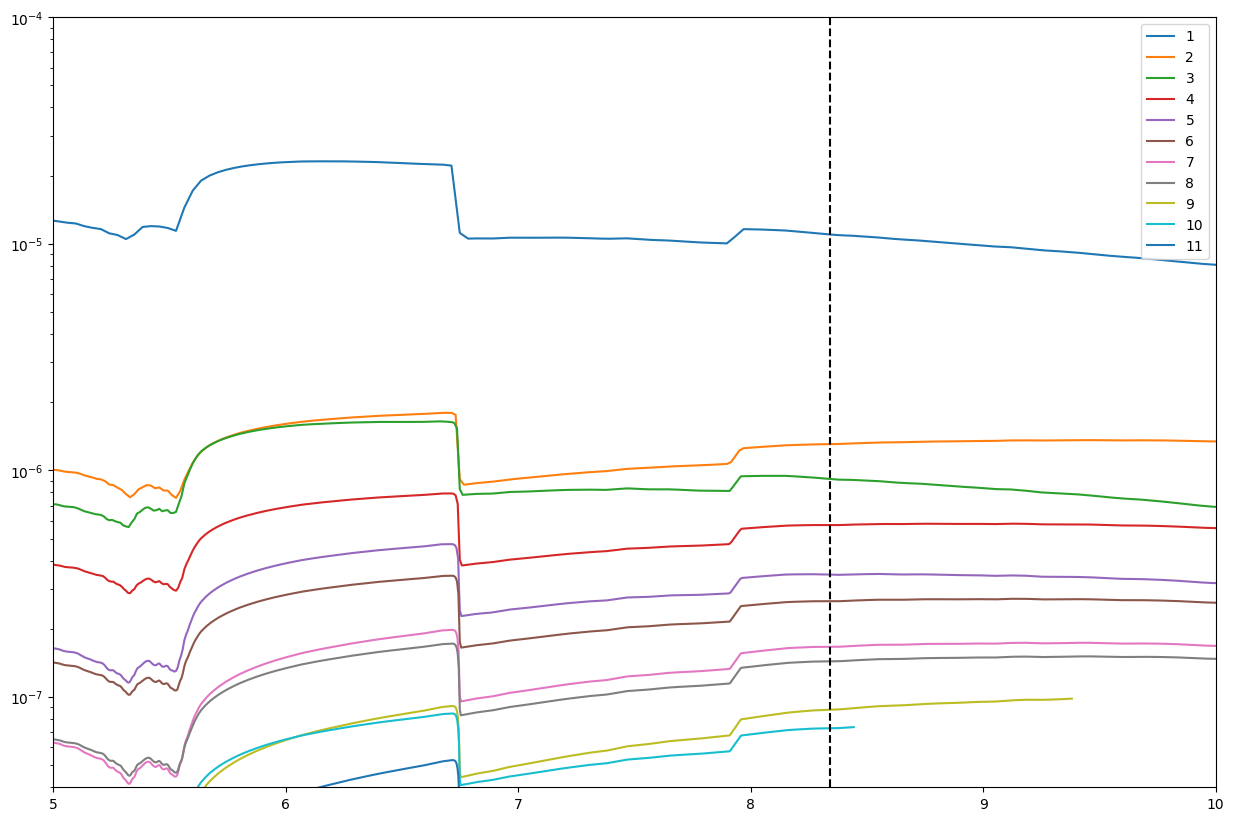

In [130]:
plt.figure(figsize=(15,10))
for mr in moxsi_built[39:]:
    plt.plot(mr.wavelength, mr.effective_area, label=mr.spectral_order)
plt.axvline(x=8.339, color='k', ls='--')
plt.xlim(5,10)
plt.yscale('log')
plt.ylim(4e-8,1e-4)
plt.legend()

In [136]:
np.interp(27.4*u.AA,moxsi_built[39].wavelength,moxsi_built[39].effective_area)

<Quantity 4.74983011e-07 cm2>

In [144]:
obs = sunpy.coordinates.get_earth(time='2020-01-01')
source_pos = astropy.coordinates.SkyCoord(Tx=0*u.arcsec, Ty=0*u.arcsec, frame=sunpy.coordinates.Helioprojective(observer=obs))
px0 = moxsi_built[38].get_wcs(get_earth('2020-01-01')).world_to_pixel(source_pos, 27.4*u.AA)[0]
delta_px = moxsi_built[39].get_wcs(get_earth('2020-01-01')).world_to_pixel(source_pos, 27.4*u.AA)[0] - px0

  'angstrom' -> 'Angstrom'. [astropy.wcs.wcs]
  'angstrom' -> 'Angstrom'. [astropy.wcs.wcs]


In [145]:
delta_px

np.float64(381.64285714285734)